# Rôle 2, tâche 8 : sensibilité du classement, TOPSIS ou somme pondérée

Deux questions :

1. **Le classement tient-il si l'on bouge un peu les poids ?** Un décideur ne sait pas dire si la rentabilité pèse 0,25 ou 0,22 : si les trois projets recommandés changent à la moindre retouche, la recommandation est fragile.
2. **Quelle méthode `rank` doit-elle utiliser ?** TOPSIS (prévue par le plan) ou la somme pondérée (référence simple).

La règle de choix a été écrite dans `docs/plan-role2.md` **avant** cette mesure (commit « Tâche 8 : règle de choix… »). Rappel :

- 500 projets en cours ; `rank` sur les 500, anomalies comprises, puis les **trois premiers projets non signalés** par `detect_anomalies`, comme le fait l'agent ;
- 14 perturbations : chaque poids multiplié par 1,2 puis 0,8, les autres ramenés pour que la somme reste 1 ;
- garde-fou : une méthode doit changer ses trois premiers pour au moins 5 des 7 profils de poids franchement différents (0,70 sur un critère, 0,05 sur les autres), sinon elle est écartée ;
- décision : la méthode dont les trois premiers changent le moins souvent ; écart de moins de 5 points : TOPSIS.


In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RACINE = Path.cwd().resolve().parents[1]  # le notebook s'exécute depuis notebooks/role2
sys.path.insert(0, str(RACINE))
logging.basicConfig(level=logging.WARNING)

from src.contrat import CRITERES, POIDS_PAR_DEFAUT, verifier_classement
from src.mcda import detect_anomalies, rank, somme_ponderee, topsis
from src.nlp import extract
from src.supervise import predict

FIGURES = RACINE / "reports" / "role2" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SORTIES = RACINE / "reports" / "role2"
pd.set_option("display.width", 140)

## 1. Les critères des 500 projets en cours

Comme l'agent : `predict` (rôle 1) donne la rentabilité prédite et la probabilité de risque élevé, `extract` (rôle 3) lit le document de chaque projet et donne les trois notes qualitatives. Les deux fonctions sont utilisées telles quelles, en lecture.

In [2]:
projets = pd.read_csv(RACINE / "data" / "processed" / "projets.csv")
en_cours = projets[projets["statut"] == "en_cours"].reset_index(drop=True)
colonnes_fiche = ["id_projet", "nom", "secteur", "pays", "region", "cout_total", "duree_mois",
                  "annee_approbation", "type_financement"]

lignes = []
for fiche in en_cours[colonnes_fiche].to_dict("records"):
    prediction = predict(fiche)
    texte = (RACINE / "data" / "docs" / f"{fiche['id_projet']}.txt").read_text(encoding="utf-8")
    notes = extract(texte)
    lignes.append({"id_projet": fiche["id_projet"],
                   "rentabilite_predite": prediction["rentabilite_predite"],
                   "proba_risque": prediction["proba_risque"],
                   "cout_total": fiche["cout_total"], "duree_mois": fiche["duree_mois"],
                   **{c: notes[c] for c in ("impact_env_social", "alignement_strategique", "faisabilite")}})
matrice = pd.DataFrame(lignes)
print(len(matrice), "projets")
matrice[list(CRITERES)].describe().round(2)

500 projets


,rentabilite_predite,proba_risque,cout_total,duree_mois,impact_env_social,alignement_strategique,faisabilite
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,7.66,0.24,457.82,68.05,4.25,4.12,4.30
std,1.99,0.23,2019.02,22.80,0.93,0.88,0.96
min,1.61,0.00,1.00,1.00,1.00,1.00,1.00
25%,6.22,0.07,40.00,60.00,4.00,4.00,4.00
50%,7.58,0.16,106.75,67.00,4.50,4.00,5.00
75%,9.07,0.35,299.25,80.00,5.00,5.00,5.00
max,13.04,0.98,37706.85,175.00,5.00,5.00,5.00


In [3]:
signales = set(detect_anomalies(en_cours).loc[lambda d: d["anomalie"], "id_projet"])
print(f"{len(signales)} projets signalés par detect_anomalies sur {len(en_cours)}")

24 projets signalés par detect_anomalies sur 500


## 2. Classer et lire les trois premiers

`classer` fait exactement ce que fait `rank` (tri par score décroissant, égalités départagées par `id_projet`), mais avec la méthode de score choisie. On vérifie qu'avec la somme pondérée elle redonne bien `rank`.

In [4]:
METHODES = {"somme pondérée": somme_ponderee, "TOPSIS": topsis}


def classer(poids: dict, methode: str) -> pd.DataFrame:
    score = METHODES[methode](matrice, poids).to_numpy()
    ordre = np.lexsort((matrice["id_projet"].to_numpy(), -score))
    sortie = matrice.iloc[ordre].copy()
    sortie["score"] = score[ordre]
    sortie["rang"] = np.arange(1, len(sortie) + 1)
    return sortie.reset_index(drop=True)


def trois_premiers(poids: dict, methode: str) -> tuple:
    classement = classer(poids, methode)
    return tuple(classement.loc[~classement["id_projet"].isin(signales), "id_projet"].head(3))


pd.testing.assert_frame_equal(classer(POIDS_PAR_DEFAUT, "somme pondérée"), rank(matrice, POIDS_PAR_DEFAUT))
verifier_classement(classer(POIDS_PAR_DEFAUT, "TOPSIS"))

reference = {m: trois_premiers(POIDS_PAR_DEFAUT, m) for m in METHODES}
reference

{'somme pondérée': ('P511001', 'P176335', 'P508608'),
 'TOPSIS': ('P511001', 'P176335', 'P176733')}

In [5]:
# Les dix premiers des deux méthodes avec les poids de référence (signalés marqués)
dix = {}
for m in METHODES:
    c = classer(POIDS_PAR_DEFAUT, m).head(10)
    dix[m] = [f"{i}{' (signalé)' if i in signales else ''}" for i in c["id_projet"]]
pd.DataFrame(dix, index=range(1, 11))

,somme pondérée,TOPSIS
1,P511001,P511001
2,P512688 (signalé),P512688 (signalé)
3,P176335,P176335
4,P508608,P176733
5,P176733,P181526
6,P180027,P181485
7,P179757,P180027
8,P510360,P174812
9,P177099,P510360
10,P172524,P179757


## 3. Garde-fou : les méthodes réagissent-elles aux poids ?

Une méthode qui garderait les mêmes trois premiers quels que soient les poids serait « stable » pour une mauvaise raison : les curseurs de l'application ne serviraient à rien. Sept profils franchement différents : 0,70 sur un critère, 0,05 sur chacun des six autres.

In [6]:
def profil(critere: str) -> dict:
    return {c: (0.70 if c == critere else 0.05) for c in CRITERES}


lignes = []
for critere in CRITERES:
    for m in METHODES:
        haut = trois_premiers(profil(critere), m)
        lignes.append({"profil (0,70 sur)": critere, "méthode": m, "trois premiers": ", ".join(haut),
                       "différents de la référence": set(haut) != set(reference[m])})
reactivite = pd.DataFrame(lignes)
reactivite.to_csv(SORTIES / "sensibilite_reactivite.csv", index=False)
bilan_reactivite = reactivite.groupby("méthode")["différents de la référence"].sum()
reactive = {m: int(bilan_reactivite[m]) >= 5 for m in METHODES}
display(reactivite)
print("Profils qui changent les trois premiers (sur 7) :", bilan_reactivite.to_dict())
print("Méthodes réactives (au moins 5 sur 7) :", reactive)

,"profil (0,70 sur)",méthode,trois premiers,différents de la référence
0,rentabilite_predite,somme pondérée,"P511001, P508608, P178347",True
1,rentabilite_predite,TOPSIS,"P511001, P508608, P178347",True
2,proba_risque,somme pondérée,"P511001, P179757, P176335",True
3,proba_risque,TOPSIS,"P511001, P173503, P179757",True
4,cout_total,somme pondérée,"P511001, P176335, P508608",False
5,cout_total,TOPSIS,"P511001, P173503, P510360",True
6,duree_mois,somme pondérée,"P511001, P511758, P509855",True
7,duree_mois,TOPSIS,"P178965, P513735, P509855",True
8,impact_env_social,somme pondérée,"P511001, P176335, P508608",False
9,impact_env_social,TOPSIS,"P511001, P176335, P507935",True


Profils qui changent les trois premiers (sur 7) : {'TOPSIS': 7, 'somme pondérée': 4}
Méthodes réactives (au moins 5 sur 7) : {'somme pondérée': False, 'TOPSIS': True}


## 4. Mesure de la règle : chaque poids à ± 20 %

Chaque poids est multiplié par 1,2 puis par 0,8 ; les six autres sont multipliés par un même facteur pour que la somme reste 1.

In [7]:
def perturber(poids: dict, critere: str, facteur: float) -> dict:
    nouveau = poids[critere] * facteur
    echelle = (1 - nouveau) / (1 - poids[critere])
    return {c: (nouveau if c == critere else p * echelle) for c, p in poids.items()}


lignes = []
for critere in CRITERES:
    for facteur in (1.2, 0.8):
        poids = perturber(POIDS_PAR_DEFAUT, critere, facteur)
        assert abs(sum(poids.values()) - 1) < 1e-9
        for m in METHODES:
            haut = trois_premiers(poids, m)
            lignes.append({"critère": critere, "facteur": facteur, "méthode": m,
                           "trois premiers": ", ".join(haut),
                           "ensemble changé": set(haut) != set(reference[m]),
                           "ordre changé": haut != reference[m]})
perturbations = pd.DataFrame(lignes)
perturbations.to_csv(SORTIES / "sensibilite_perturbations.csv", index=False)
bilan = perturbations.groupby("méthode")[["ensemble changé", "ordre changé"]].sum()
bilan["part des 14 (ensemble changé)"] = (bilan["ensemble changé"] / 14 * 100).round(1)
bilan

,ensemble changé,ordre changé,part des 14 (ensemble changé)
méthode,,,
TOPSIS,0,0,0.0
somme pondérée,0,2,0.0


In [8]:
perturbations.pivot_table(index=["critère", "facteur"], columns="méthode",
                          values="ensemble changé", aggfunc="first")

méthode                         TOPSIS  somme pondérée
critère                facteur                        
alignement_strategique 0.8       False           False
                       1.2       False           False
cout_total             0.8       False           False
                       1.2       False           False
duree_mois             0.8       False           False
                       1.2       False           False
faisabilite            0.8       False           False
                       1.2       False           False
impact_env_social      0.8       False           False
                       1.2       False           False
proba_risque           0.8       False           False
                       1.2       False           False
rentabilite_predite    0.8       False           False
                       1.2       False           False

## 5. Décision, par la règle écrite à l'avance

In [9]:
part = bilan["part des 14 (ensemble changé)"].to_dict()
candidates = [m for m in METHODES if reactive[m]]
if not candidates:
    choix, raison = "TOPSIS", "aucune méthode réactive : TOPSIS par défaut (plan commun)"
elif len(candidates) == 1:
    choix, raison = candidates[0], "seule méthode réactive"
elif abs(part["TOPSIS"] - part["somme pondérée"]) < 5:
    choix, raison = "TOPSIS", "écart de moins de 5 points : TOPSIS (plan commun)"
else:
    choix = min(candidates, key=part.get)
    raison = "trois premiers moins souvent changés sous ± 20 %"
print(f"Part des perturbations qui changent les trois premiers : {part}")
print(f"Méthode retenue pour rank : {choix} ({raison})")

Part des perturbations qui changent les trois premiers : {'TOPSIS': 0.0, 'somme pondérée': 0.0}
Méthode retenue pour rank : TOPSIS (seule méthode réactive)


## 6. Compléments pour le rapport (ils ne changent pas la décision)

### 6.1 Tous les poids bougent à la fois : 1 000 tirages

Chaque poids est multiplié par un nombre tiré entre 0,8 et 1,2, puis l'ensemble est ramené à une somme de 1 (graine 42).

In [10]:
rng = np.random.default_rng(42)
w0 = np.array([POIDS_PAR_DEFAUT[c] for c in CRITERES])
changes = {m: 0 for m in METHODES}
apparitions = {m: {} for m in METHODES}
N = 1000
for _ in range(N):
    w = w0 * rng.uniform(0.8, 1.2, size=len(w0))
    poids = dict(zip(CRITERES, w / w.sum()))
    for m in METHODES:
        haut = trois_premiers(poids, m)
        changes[m] += set(haut) != set(reference[m])
        for i in haut:
            apparitions[m][i] = apparitions[m].get(i, 0) + 1
aleatoire = pd.DataFrame({"part des tirages où les trois premiers changent (%)":
                          {m: round(100 * changes[m] / N, 1) for m in METHODES}})
aleatoire.to_csv(SORTIES / "sensibilite_tirages.csv")
aleatoire

,part des tirages où les trois premiers changent (%)
somme pondérée,0.0
TOPSIS,3.8


In [11]:
# Projets les plus souvent dans les trois premiers sur les 1 000 tirages
for m in METHODES:
    top = sorted(apparitions[m].items(), key=lambda kv: -kv[1])[:6]
    print(m, ":", ", ".join(f"{i} ({100 * n / N:.0f} %)" for i, n in top))

somme pondérée : P511001 (100 %), P508608 (100 %), P176335 (100 %)
TOPSIS : P511001 (100 %), P176335 (100 %), P176733 (96 %), P181526 (4 %)


### 6.2 Les deux méthodes classent-elles pareil ?

Corrélation de Spearman entre les rangs des 500 projets (poids de référence) : 1 si les deux classements sont identiques, 0 s'ils n'ont aucun rapport. Calculée comme la corrélation de Pearson entre les rangs.

In [12]:
rangs = pd.DataFrame({m: classer(POIDS_PAR_DEFAUT, m).set_index("id_projet")["rang"] for m in METHODES})
spearman = rangs["somme pondérée"].corr(rangs["TOPSIS"])
communs_10 = len(set(rangs.nsmallest(10, "somme pondérée").index) & set(rangs.nsmallest(10, "TOPSIS").index))
communs_50 = len(set(rangs.nsmallest(50, "somme pondérée").index) & set(rangs.nsmallest(50, "TOPSIS").index))
print(f"Spearman = {spearman:.3f} ; projets communs dans les 10 premiers : {communs_10} ; dans les 50 premiers : {communs_50}")
ecart = (rangs["TOPSIS"] - rangs["somme pondérée"])
print(f"Écart de rang médian : {ecart.abs().median():.0f} places ; plus grand écart : {ecart.abs().max()} places")

Spearman = 0.736 ; projets communs dans les 10 premiers : 7 ; dans les 50 premiers : 29
Écart de rang médian : 72 places ; plus grand écart : 324 places


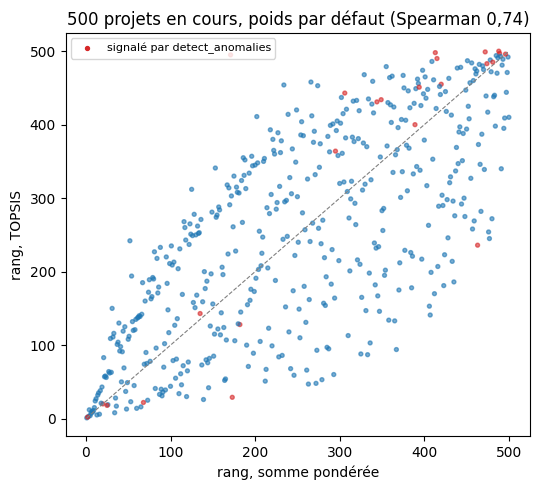

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 5))
couleur = np.where(rangs.index.isin(signales), "tab:red", "tab:blue")
ax.scatter(rangs["somme pondérée"], rangs["TOPSIS"], s=8, c=couleur, alpha=0.6)
ax.plot([1, 500], [1, 500], color="grey", lw=0.8, ls="--")
ax.set_xlabel("rang, somme pondérée")
ax.set_ylabel("rang, TOPSIS")
ax.set_title(f"500 projets en cours, poids par défaut (Spearman {spearman:.2f})".replace(".", ","))
ax.scatter([], [], c="tab:red", s=8, label="signalé par detect_anomalies")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "rangs_topsis_somme.png", dpi=150)
plt.show()

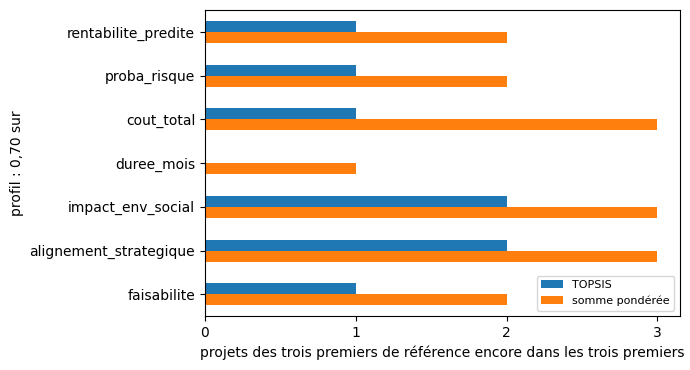

In [14]:
# Réactivité : combien des trois premiers de référence restent en place pour chaque profil
reactivite["conservés (sur 3)"] = [len(set(h.split(", ")) & set(reference[m]))
                                   for h, m in zip(reactivite["trois premiers"], reactivite["méthode"])]
tableau = reactivite.pivot_table(index="profil (0,70 sur)", columns="méthode", values="conservés (sur 3)")
fig, ax = plt.subplots(figsize=(7, 3.8))
tableau.reindex(list(CRITERES)).plot.barh(ax=ax)
ax.set_xlabel("projets des trois premiers de référence encore dans les trois premiers")
ax.set_xticks([0, 1, 2, 3])
ax.set_ylabel("profil : 0,70 sur")
ax.invert_yaxis()
ax.legend(title="", loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "reactivite_profils.png", dpi=150)
plt.show()

In [15]:
# Les anomalies changent-elles la normalisation ? Écart d'étendue avec et sans les projets signalés
non_signales = ~matrice["id_projet"].isin(signales)
pd.DataFrame({"étendue, 500 projets": matrice[list(CRITERES)].max() - matrice[list(CRITERES)].min(),
              "étendue, sans les signalés": matrice.loc[non_signales, list(CRITERES)].max()
              - matrice.loc[non_signales, list(CRITERES)].min()}).round(2)

,"étendue, 500 projets","étendue, sans les signalés"
rentabilite_predite,11.43,10.63
proba_risque,0.98,0.97
cout_total,37705.85,2781.10
duree_mois,174.00,131.00
impact_env_social,4.00,4.00
alignement_strategique,4.00,4.00
faisabilite,4.00,4.00


## 7. Conclusion

**Décision (règle écrite avant la mesure) : `rank` utilisera TOPSIS.** Ce n'est pas la stabilité qui départage les deux méthodes, c'est le garde-fou :

- **Stabilité sous ± 20 %** : les deux méthodes sont très stables. Aucune des 14 perturbations ne change l'ensemble des trois premiers, ni pour TOPSIS ni pour la somme pondérée (la somme pondérée échange deux fois l'ordre entre eux). Sur 1 000 tirages où tous les poids bougent à la fois, les trois premiers changent dans 0 % des cas pour la somme pondérée et 3,8 % pour TOPSIS (le troisième, P176733, laisse sa place à P181526).
- **Réactivité aux poids** : TOPSIS change ses trois premiers pour les 7 profils franchement différents ; la somme pondérée pour 4 seulement. Mettre 0,70 sur le coût, sur l'impact ou sur l'alignement ne change pas ses trois premiers. Elle est donc écartée par la règle (seuil : 5 profils sur 7) : sa stabilité vient en partie de ce qu'elle ignore certains curseurs.

**Pourquoi la somme pondérée ignore le coût.** La normalisation min-max se cale sur le plus petit et le plus grand coût des 500 projets. Le plus grand, 37 707 M$, est un coût aberrant (signalé par `detect_anomalies`, mais gardé dans le classement comme le fait l'agent). Les projets non signalés coûtent tous moins de 2 800 M$ : leur coût ramené entre 0 et 1 vaut presque 1 pour tous, et le poids du coût ne les départage plus. Les notes qualitatives, elles, sont souvent au maximum (la moitié des projets a 5 en faisabilité), ce qui laisse peu de place pour changer le haut du classement. TOPSIS divise par la norme et mesure des distances à l'idéal : il reste sensible à ces critères.

**Les deux méthodes ne classent pas pareil** : corrélation de Spearman de 0,74 entre les deux classements des 500 projets, 7 projets communs dans les 10 premiers, 29 dans les 50 premiers, écart médian de 72 places. Le haut du classement est proche (même premier, même deuxième non signalé), le milieu beaucoup moins.

**Rôle des anomalies.** Le deuxième projet des deux classements, P512688, est signalé par `detect_anomalies` : il est écarté de la recommandation, comme le prévoit l'agent.

**Limites.**

- 14 perturbations, c'est peu : avec 0 changement des deux côtés, la mesure de stabilité ne départage rien ; le choix repose sur le garde-fou.
- Le résultat dépend des notes de `extract` et des prédictions de `predict` : si ces modules changent, il faudra refaire la mesure (le notebook se relance tel quel).
- Une amélioration possible de la somme pondérée serait de normaliser le log du coût, ou de calculer les bornes sans les projets signalés ; elle n'a pas été essayée ici, pour ne pas ajuster la méthode après avoir vu le résultat.
- Le passage de `rank` à TOPSIS se fait dans une branche à part (tâche 9).
